# 01. Preprocessing
AI Hub images → face crop & alignment (MediaPipe) → per-emotion 75/15/10 split → train augmentation → FaceMesh landmarks → Z-features → TFRecord.

Sample-face visualisations are omitted (dataset licence).

In [ ]:
 # Google Drive 마운트
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install mediapipe

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 34.8/34.8 MB 28.6 MB/s eta 0:00:00


## 1. Face crop & alignment

In [ ]:
import os
import cv2
import numpy as np
import tensorflow as tf
import mediapipe as mp

# Mediapipe 초기화
mp_face_detection = mp.solutions.face_detection
face_detection = mp_face_detection.FaceDetection(min_detection_confidence=0.2)

# 감정 라벨과 디렉토리 매핑
emotion_directories = {
    "anger": "/content/drive/MyDrive/clean_0317/Dataset_clean/clean_anger",
    "disgust": "/content/drive/MyDrive/clean_0317/Dataset_clean/clean_disgust",
    "fear": "/content/drive/MyDrive/clean_0317/Dataset_clean/clean_fear",
    "happy": "/content/drive/MyDrive/clean_0317/Dataset_clean/clean_happy",
    "neutral": "/content/drive/MyDrive/clean_0317/Dataset_clean/clean_neutral",
    "sad": "/content/drive/MyDrive/clean_0317/Dataset_clean/clean_sad",
    "surprise": "/content/drive/MyDrive/clean_0317/Dataset_clean/clean_surprise"
}

emotion_labels = {
    "happy": 0,
    "sad": 1,
    "anger": 2,
    "surprise": 3,
    "disgust": 4,
    "neutral": 5,
    "fear": 6,
}

# TFRecord 특성 생성 함수
def _bytes_feature(value):
    return tf.train.Feature(bytes_list=tf.train.BytesList(value=[tf.io.encode_jpeg(value).numpy()]))

def _int64_feature(value):
    return tf.train.Feature(int64_list=tf.train.Int64List(value=[value]))

def get_label(folder_path):
    for emotion, label in emotion_labels.items():
        if emotion in folder_path:
            return label
    return -1

def correct_rotation(image):
    """얼굴의 회전을 보정하는 함수"""
    results = face_detection.process(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    if results.detections:
        for detection in results.detections:
            landmarks = detection.location_data.relative_keypoints
            left_eye = landmarks[0]
            right_eye = landmarks[1]

            left_eye_pos = (left_eye.x * image.shape[1], left_eye.y * image.shape[0])
            right_eye_pos = (right_eye.x * image.shape[1], right_eye.y * image.shape[0])

            dy = right_eye_pos[1] - left_eye_pos[1]
            dx = right_eye_pos[0] - left_eye_pos[0]
            angle = np.degrees(np.arctan2(dy, dx))

            center = (image.shape[1] // 2, image.shape[0] // 2)
            M = cv2.getRotationMatrix2D(center, angle, 1)
            rotated_image = cv2.warpAffine(image, M, (image.shape[1], image.shape[0]))

            return rotated_image
    return image  # 얼굴이 감지되지 않으면 원본 반환

def process_image(image_file, writer, total_images, current_count):
    """이미지를 처리하여 얼굴을 크롭하고 TFRecord로 저장하는 함수"""
    try:
        image = cv2.imread(image_file)
        if image is None:
            return

        # 얼굴 회전 보정
        corrected_image = correct_rotation(image)
        results = face_detection.process(cv2.cvtColor(corrected_image, cv2.COLOR_BGR2RGB))

        if results.detections:
            for detection in results.detections:
                bboxC = detection.location_data.relative_bounding_box
                ih, iw, _ = corrected_image.shape
                x, y, w, h = (
                    int(bboxC.xmin * iw),
                    int(bboxC.ymin * ih),
                    int(bboxC.width * iw),
                    int(bboxC.height * ih),
                )

                # 얼굴 주변에 마진 추가 (원본 해상도 기준)
                margin_x = int(w * 0.1)  # 가로 여백 (얼굴 크기의 50%)
                margin_y = int(h * 0.1)  # 세로 여백

                x1 = max(0, x - margin_x)
                y1 = max(0, y - margin_y)
                x2 = min(iw, x + w + margin_x)
                y2 = min(ih, y + h + margin_y)

                # 얼굴 + 배경 포함 크롭
                cropped_image = corrected_image[y1:y2, x1:x2]

                # 500x500 크기로 패딩 (비율 유지)
                target_size = 500
                h_new, w_new, _ = cropped_image.shape
                max_dim = max(h_new, w_new)
                scale = target_size / max_dim
                new_w = int(w_new * scale)
                new_h = int(h_new * scale)
                resized_image = cv2.resize(cropped_image, (new_w, new_h))

                # 중앙 정렬을 위해 500x500 캔버스 생성
                canvas = np.ones((target_size, target_size, 3), dtype=np.uint8) * 255  # 흰색 배경
                start_x = (target_size - new_w) // 2
                start_y = (target_size - new_h) // 2
                canvas[start_y:start_y+new_h, start_x:start_x+new_w] = resized_image

                # 64x64로 리사이징
                final_image = cv2.resize(canvas, (64, 64))

                # TFRecord 저장
                feature = {
                    "image": _bytes_feature(final_image),
                    "label": _int64_feature(get_label(image_file)),
                }
                example_proto = tf.train.Example(features=tf.train.Features(feature=feature))
                writer.write(example_proto.SerializeToString())

    except Exception as e:
        print(f"Error processing image {image_file}: {e}")

    # 현재 진행 상황 출력
    print(f"Processed {current_count}/{total_images} images")

# TFRecord 저장 디렉토리
output_dir = "/content/drive/MyDrive/01_27_new"

# 감정별 디렉토리를 순회하며 이미지 처리
for emotion, dir_path in emotion_directories.items():
    image_files = [
        os.path.join(dir_path, filename)
        for filename in os.listdir(dir_path)
        if filename.endswith((".jpg", ".png", ".jpeg"))
    ]

    tfrecord_filename = os.path.join(output_dir, f"0129_no_AUG_{emotion}.tfrecord")

    with tf.io.TFRecordWriter(tfrecord_filename) as writer:
        for count, image_file in enumerate(image_files, start=1):
            process_image(image_file, writer, len(image_files), count)

print("All images processed and saved to TFRecord format!")


Streaming output truncated to the last 5000 lines.
Processed 906/5904 images
Processed 907/5904 images
Processed 908/5904 images
Processed 909/5904 images
...
Processed 5867/5904 images
Processed 5868/5904 images
Processed 5869/5904 images
Processed 5870/5904 images
Processed 5871/5904 images
Processed 5872/5904 images
Processed 5873/5904 images
Processed 5874/5904 images
Processed 5875/5904 images
Processed 5876/5904 images
Processed 5877/5904 images
Processed 5878/5904 images
Processed 5879/5904 images
Processed 5880/5904 images
Processed 5881/5904 images
Processed 5882/5904 images
Processed 5883/5904 images
Processed 5884/5904 images
Processed 5885/5904 images
Processed 5886/5904 images
Processed 5887/5904 images
Processed 5888/5904 images
Processed 5889/5904 images
Processed 5890/5904 images
Processed 5891/5904 images
Processed 5892/5904 images
Processed 5893/5904 images
Processed 5894/5904 images
Processed 5895/5904 images
Processed 5896/5904 images
Processed 5897/5904 images
Proc

## 2. Train / val / test split

In [ ]:
import tensorflow as tf
import os
import functools

def split_tfrecord(tfrecord_path, train_ratio, val_ratio):
    # 데이터셋 로드
    dataset = tf.data.TFRecordDataset(tfrecord_path)
    dataset_size = sum(1 for _ in dataset)

    # 각 데이터셋의 크기 계산
    train_size = int(train_ratio * dataset_size)
    val_size = int(val_ratio * dataset_size)
    test_size = dataset_size - train_size - val_size

    # 데이터셋 분할
    train_dataset = dataset.take(train_size)
    remaining_dataset = dataset.skip(train_size)
    val_dataset = remaining_dataset.take(val_size)
    test_dataset = remaining_dataset.skip(val_size)

    return train_dataset, val_dataset, test_dataset

def write_tfrecord(dataset, filename):
    writer = tf.io.TFRecordWriter(filename)
    for record in dataset:
        writer.write(record.numpy())
    writer.close()

def concatenate_datasets(datasets):
    # functools.reduce를 사용하여 데이터셋들을 순차적으로 병합
    return functools.reduce(lambda a, b: a.concatenate(b), datasets)

# 파일 경로 설정
file_paths = [
    '/content/drive/MyDrive/01_27_new/0129_no_AUG_anger.tfrecord',
    '/content/drive/MyDrive/01_27_new/0129_no_AUG_disgust.tfrecord',
    '/content/drive/MyDrive/01_27_new/0129_no_AUG_fear.tfrecord',
    '/content/drive/MyDrive/01_27_new/0129_no_AUG_happy.tfrecord',
    '/content/drive/MyDrive/01_27_new/0129_no_AUG_neutral.tfrecord',
    '/content/drive/MyDrive/01_27_new/0129_no_AUG_sad.tfrecord',
    '/content/drive/MyDrive/01_27_new/0129_no_AUG_surprise.tfrecord'
]

# 빈 데이터셋 생성
train_datasets, val_datasets, test_datasets = [], [], []

# 각 파일 처리
for file_path in file_paths:
    train, val, test = split_tfrecord(file_path, 0.75, 0.15)
    train_datasets.append(train)
    val_datasets.append(val)
    test_datasets.append(test)

# 데이터셋 병합
train_dataset = concatenate_datasets(train_datasets)
val_dataset = concatenate_datasets(val_datasets)
test_dataset = concatenate_datasets(test_datasets)

# 저장 경로 설정
output_dir = '/content/drive/MyDrive/01_27_new'
os.makedirs(output_dir, exist_ok=True)

# 새로운 TFRecord 파일로 저장
write_tfrecord(train_dataset, os.path.join(output_dir, '0127_NOLAND_train.tfrecord'))
write_tfrecord(val_dataset, os.path.join(output_dir, '0127_NOLAND_val.tfrecord'))
write_tfrecord(test_dataset, os.path.join(output_dir, '0127_NOLAND_test.tfrecord'))


## 3. Train augmentation

In [ ]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# TFRecord 파일에서 이미지와 라벨 추출
def parse_tfrecord_fn(example):
    feature_description = {
        'image': tf.io.FixedLenFeature([], tf.string),
        'label': tf.io.FixedLenFeature([], tf.int64),
    }
    parsed_features = tf.io.parse_single_example(example, feature_description)
    image = tf.io.decode_jpeg(parsed_features['image'])
    label = parsed_features['label']
    return image, label

# 이미지 증강 함수 정의
def augment_image(image, datagen):
    image = np.expand_dims(image, axis=0)  # 배치 형태로 변경
    it = datagen.flow(image, batch_size=1)
    image_aug = next(it)  # 🔥 `.next()` 대신 `next(it)` 사용
    return image_aug[0]

def write_augmented_tfrecord(input_tfrecord_path, output_tfrecord_path, datagen):
    with tf.io.TFRecordWriter(output_tfrecord_path) as writer:
        for raw_record in tf.data.TFRecordDataset(input_tfrecord_path):
            image, label = parse_tfrecord_fn(raw_record)

            # 원본 이미지 저장
            image_string = tf.io.encode_jpeg(tf.cast(image, tf.uint8)).numpy()
            original_feature = {
                'image': tf.train.Feature(bytes_list=tf.train.BytesList(value=[image_string])),
                'label': tf.train.Feature(int64_list=tf.train.Int64List(value=[label.numpy()])),
            }
            original_example = tf.train.Example(features=tf.train.Features(feature=original_feature))
            writer.write(original_example.SerializeToString())

            # 증강된 이미지 저장
            image_aug = augment_image(image.numpy(), datagen)
            image_string_aug = tf.io.encode_jpeg(tf.cast(image_aug, tf.uint8)).numpy()
            augmented_feature = {
                'image': tf.train.Feature(bytes_list=tf.train.BytesList(value=[image_string_aug])),
                'label': tf.train.Feature(int64_list=tf.train.Int64List(value=[label.numpy()])),
            }
            augmented_example = tf.train.Example(features=tf.train.Features(feature=augmented_feature))
            writer.write(augmented_example.SerializeToString())

# ImageDataGenerator 정의
datagen = ImageDataGenerator(
    rotation_range=5,
    zoom_range=0.05,
    width_shift_range=0.05,
    height_shift_range=0.05,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2]
)

output_dir = '/content/drive/MyDrive/01_27_new'
train_tfrecord_path = '/content/drive/MyDrive/01_27_new/0127_NOLAND_train.tfrecord'

# 증강된 이미지를 저장할 새로운 TFRecord 파일 경로
augmented_tfrecord_path = '/content/drive/MyDrive/01_27_new/0127_NOLAND_train_augmented.tfrecord'

# 증강된 데이터를 새로운 TFRecord 파일에 저장
write_augmented_tfrecord(train_tfrecord_path, augmented_tfrecord_path, datagen)


## 4. Shuffle

In [ ]:
import tensorflow as tf

# TFRecord 파싱 함수
def _parse_function(proto):
    feature_description = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "landmarks": tf.io.VarLenFeature(tf.float32),
        "label": tf.io.FixedLenFeature([], tf.int64),
    }
    return tf.io.parse_single_example(proto, feature_description)

# 특성을 tf.train.Feature로 변환하는 함수
def _bytes_feature(value):
    if isinstance(value, type(tf.constant(0))):
        value = value.numpy()  # BytesList는 EagerTensor에서 바이트 문자열을 처리하지 않습니다.
    return tf.train.Feature(bytes_list=tf.train.BytesList(value=[value]))

def _int64_feature(value):
    return tf.train.Feature(int64_list=tf.train.Int64List(value=[value]))

# 원본 TFRecord 파일 경로
original_tfrecord_path = '/content/drive/MyDrive/01_27_new/0127_NOLAND_train_augmented.tfrecord'

# TFRecord 데이터셋 로드 및 파싱
raw_dataset = tf.data.TFRecordDataset(original_tfrecord_path)
parsed_dataset = raw_dataset.map(_parse_function)

# 데이터셋 셔플
shuffled_dataset = parsed_dataset.shuffle(buffer_size=5000)

# 새로운 TFRecord 파일로 저장
new_tfrecord_path = '/content/drive/MyDrive/01_27_new/shuffled_0127_NOLAND_train_augmented.tfrecord'
with tf.io.TFRecordWriter(new_tfrecord_path) as writer:
    for parsed_record in shuffled_dataset:
        features = {
            "image": _bytes_feature(parsed_record["image"]),
            "label": _int64_feature(parsed_record["label"])
        }
        tf_example = tf.train.Example(features=tf.train.Features(feature=features))
        writer.write(tf_example.SerializeToString())


In [ ]:
import tensorflow as tf

# TFRecord 파싱 함수
def _parse_function(proto):
    feature_description = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "landmarks": tf.io.VarLenFeature(tf.float32),
        "label": tf.io.FixedLenFeature([], tf.int64),
    }
    return tf.io.parse_single_example(proto, feature_description)

# 특성을 tf.train.Feature로 변환하는 함수
def _bytes_feature(value):
    if isinstance(value, type(tf.constant(0))):
        value = value.numpy()  # BytesList는 EagerTensor에서 바이트 문자열을 처리하지 않습니다.
    return tf.train.Feature(bytes_list=tf.train.BytesList(value=[value]))

def _int64_feature(value):
    return tf.train.Feature(int64_list=tf.train.Int64List(value=[value]))

# 원본 TFRecord 파일 경로
original_tfrecord_path = '/content/drive/MyDrive/01_27_new/shuffled_0127_NOLAND_train_augmented.tfrecord'

# TFRecord 데이터셋 로드 및 파싱
raw_dataset = tf.data.TFRecordDataset(original_tfrecord_path)
parsed_dataset = raw_dataset.map(_parse_function)

# 데이터셋 셔플
shuffled_dataset = parsed_dataset.shuffle(buffer_size=5000)

# 새로운 TFRecord 파일로 저장
new_tfrecord_path = '/content/drive/MyDrive/01_27_new/2_shuffled_0127_NOLAND_train_augmented.tfrecord'
with tf.io.TFRecordWriter(new_tfrecord_path) as writer:
    for parsed_record in shuffled_dataset:
        features = {
            "image": _bytes_feature(parsed_record["image"]),
            "label": _int64_feature(parsed_record["label"])
        }
        tf_example = tf.train.Example(features=tf.train.Features(feature=features))
        writer.write(tf_example.SerializeToString())


## 5. Landmark extraction (FaceMesh)

In [ ]:
import os
import cv2
import numpy as np
import logging
import tensorflow as tf
import mediapipe as mp
from google.colab.patches import cv2_imshow

# 로깅 설정
logging.basicConfig(filename="error_log.txt", level=logging.ERROR)

# mediapipe 초기화
mp_face_detection = mp.solutions.face_detection
face_detection = mp_face_detection.FaceDetection(min_detection_confidence=0.2)
mp_face_mesh = mp.solutions.face_mesh
face_mesh = mp_face_mesh.FaceMesh()

# .tfrecord 파일 경로 설정
tfrecord_file_path = '/content/drive/MyDrive/01_27_new/2_shuffled_0127_NOLAND_train_augmented.tfrecord'
def _bytes_feature(value):
    return tf.train.Feature(bytes_list=tf.train.BytesList(value=[tf.io.encode_jpeg(value).numpy()]))

def _int64_feature(value):
    return tf.train.Feature(int64_list=tf.train.Int64List(value=[value]))

# TFRecord 파싱 함수
def parse_tfrecord_function(example_proto):
    feature_description = {
        'image': tf.io.FixedLenFeature([], tf.string),
        'label': tf.io.FixedLenFeature([], tf.int64)
    }
    return tf.io.parse_single_example(example_proto, feature_description)

# 이미지 디코딩 함수
def decode_image(image_str):
    image = tf.image.decode_jpeg(image_str, channels=3)
    return image.numpy()  # TensorFlow 텐서를 NumPy 배열로 변환

# TFRecord 파일 로드 및 파싱
raw_dataset = tf.data.TFRecordDataset(tfrecord_file_path)
parsed_dataset = raw_dataset.map(parse_tfrecord_function)

# 이미지 데이터와 라벨을 담을 리스트
image_data = []

# 각 레코드 처리
for parsed_record in parsed_dataset:
    image_str = parsed_record['image'].numpy()
    image = decode_image(image_str)
    label = parsed_record['label'].numpy()
    image_data.append((image, label))

# TFRecord에 저장할 랜드마크 좌표 저장 함수
def _float_feature(value):
    return tf.train.Feature(float_list=tf.train.FloatList(value=value))

def get_landmarks(image):
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    results = face_mesh.process(image_rgb)
    if results.multi_face_landmarks:
        landmarks = []
        for face_landmarks in results.multi_face_landmarks:
            for landmark in face_landmarks.landmark:
                landmarks.extend([landmark.x, landmark.y, landmark.z])
        return landmarks
    return []

def process_image(image_data, writer):
    for i, (image, label) in enumerate(image_data):
        try:
            if image is None:
                logging.error("Error processing image: Image is None")
                continue
            # 얼굴 랜드마크 추출
            landmarks = get_landmarks(image)
            # TFrecord에 저장할 특성 정의 및 저장
            feature = {
                "image": _bytes_feature(image),
                "landmarks": _float_feature(landmarks),
                "label": _int64_feature(label)
            }
            example_proto = tf.train.Example(features=tf.train.Features(feature=feature))
            writer.write(example_proto.SerializeToString())
            progress = (i + 1) / len(image_data) * 100
            print(f"Processing image {i + 1}/{len(image_data)} ({progress:.2f}%)")
        except Exception as e:
            logging.error(f"Error processing image: {e}", exc_info=True)

# TFRecord 파일 생성 및 이미지 처리
output_tfrecord_file_path = '/content/drive/MyDrive/01_27_new/0127_NO_Z_train_augmented.tfrecord'
with tf.io.TFRecordWriter(output_tfrecord_file_path) as writer:
    process_image(image_data, writer)


Streaming output truncated to the last 5000 lines.
Processing image 66365/71364 (93.00%)
Processing image 66366/71364 (93.00%)
Processing image 66367/71364 (93.00%)
Processing image 66368/71364 (93.00%)
...
Processing image 71326/71364 (99.95%)
Processing image 71327/71364 (99.95%)
Processing image 71328/71364 (99.95%)
Processing image 71329/71364 (99.95%)
Processing image 71330/71364 (99.95%)
Processing image 71331/71364 (99.95%)
Processing image 71332/71364 (99.96%)
Processing image 71333/71364 (99.96%)
Processing image 71334/71364 (99.96%)
Processing image 71335/71364 (99.96%)
Processing image 71336/71364 (99.96%)
Processing image 71337/71364 (99.96%)
Processing image 71338/71364 (99.96%)
Processing image 71339/71364 (99.96%)
Processing image 71340/71364 (99.97%)
Processing image 71341/71364 (99.97%)
Processing image 71342/71364 (99.97%)
Processing image 71343/71364 (99.97%)
Processing image 71344/71364 (99.97%)
Processing image 71345/71364 (99.97%)
Processing image 71346/71364 (99.

In [ ]:
import os
import cv2
import numpy as np
import logging
import tensorflow as tf
import mediapipe as mp
from google.colab.patches import cv2_imshow

# 로깅 설정
logging.basicConfig(filename="error_log.txt", level=logging.ERROR)

# mediapipe 초기화
mp_face_detection = mp.solutions.face_detection
face_detection = mp_face_detection.FaceDetection(min_detection_confidence=0.2)
mp_face_mesh = mp.solutions.face_mesh
face_mesh = mp_face_mesh.FaceMesh()

# .tfrecord 파일 경로 설정
tfrecord_file_path = '/content/drive/MyDrive/01_27_new/0127_NOLAND_val.tfrecord'
def _bytes_feature(value):
    return tf.train.Feature(bytes_list=tf.train.BytesList(value=[tf.io.encode_jpeg(value).numpy()]))

def _int64_feature(value):
    return tf.train.Feature(int64_list=tf.train.Int64List(value=[value]))

# TFRecord 파싱 함수
def parse_tfrecord_function(example_proto):
    feature_description = {
        'image': tf.io.FixedLenFeature([], tf.string),
        'label': tf.io.FixedLenFeature([], tf.int64)
    }
    return tf.io.parse_single_example(example_proto, feature_description)

# 이미지 디코딩 함수
def decode_image(image_str):
    image = tf.image.decode_jpeg(image_str, channels=3)
    return image.numpy()  # TensorFlow 텐서를 NumPy 배열로 변환

# TFRecord 파일 로드 및 파싱
raw_dataset = tf.data.TFRecordDataset(tfrecord_file_path)
parsed_dataset = raw_dataset.map(parse_tfrecord_function)

# 이미지 데이터와 라벨을 담을 리스트
image_data = []

# 각 레코드 처리
for parsed_record in parsed_dataset:
    image_str = parsed_record['image'].numpy()
    image = decode_image(image_str)
    label = parsed_record['label'].numpy()
    image_data.append((image, label))

# TFRecord에 저장할 랜드마크 좌표 저장 함수
def _float_feature(value):
    return tf.train.Feature(float_list=tf.train.FloatList(value=value))

def get_landmarks(image):
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    results = face_mesh.process(image_rgb)
    if results.multi_face_landmarks:
        landmarks = []
        for face_landmarks in results.multi_face_landmarks:
            for landmark in face_landmarks.landmark:
                landmarks.extend([landmark.x, landmark.y, landmark.z])
        return landmarks
    return []

def process_image(image_data, writer):
    for i, (image, label) in enumerate(image_data):
        try:
            if image is None:
                logging.error("Error processing image: Image is None")
                continue
            # 얼굴 랜드마크 추출
            landmarks = get_landmarks(image)
            # TFrecord에 저장할 특성 정의 및 저장
            feature = {
                "image": _bytes_feature(image),
                "landmarks": _float_feature(landmarks),
                "label": _int64_feature(label)
            }
            example_proto = tf.train.Example(features=tf.train.Features(feature=feature))
            writer.write(example_proto.SerializeToString())
            progress = (i + 1) / len(image_data) * 100
            print(f"Processing image {i + 1}/{len(image_data)} ({progress:.2f}%)")
        except Exception as e:
            logging.error(f"Error processing image: {e}", exc_info=True)

# TFRecord 파일 생성 및 이미지 처리
output_tfrecord_file_path = '/content/drive/MyDrive/01_27_new/0127_NO_Z_val.tfrecord'
with tf.io.TFRecordWriter(output_tfrecord_file_path) as writer:
    process_image(image_data, writer)


Streaming output truncated to the last 5000 lines.
Processing image 2133/7132 (29.91%)
Processing image 2134/7132 (29.92%)
Processing image 2135/7132 (29.94%)
Processing image 2136/7132 (29.95%)
...
Processing image 7094/7132 (99.47%)
Processing image 7095/7132 (99.48%)
Processing image 7096/7132 (99.50%)
Processing image 7097/7132 (99.51%)
Processing image 7098/7132 (99.52%)
Processing image 7099/7132 (99.54%)
Processing image 7100/7132 (99.55%)
Processing image 7101/7132 (99.57%)
Processing image 7102/7132 (99.58%)
Processing image 7103/7132 (99.59%)
Processing image 7104/7132 (99.61%)
Processing image 7105/7132 (99.62%)
Processing image 7106/7132 (99.64%)
Processing image 7107/7132 (99.65%)
Processing image 7108/7132 (99.66%)
Processing image 7109/7132 (99.68%)
Processing image 7110/7132 (99.69%)
Processing image 7111/7132 (99.71%)
Processing image 7112/7132 (99.72%)
Processing image 7113/7132 (99.73%)
Processing image 7114/7132 (99.75%)
Processing image 7115/7132 (99.76%)
Processin

In [ ]:
import os
import cv2
import numpy as np
import logging
import tensorflow as tf
import mediapipe as mp
from google.colab.patches import cv2_imshow

# 로깅 설정
logging.basicConfig(filename="error_log.txt", level=logging.ERROR)

# mediapipe 초기화
mp_face_detection = mp.solutions.face_detection
face_detection = mp_face_detection.FaceDetection(min_detection_confidence=0.2)
mp_face_mesh = mp.solutions.face_mesh
face_mesh = mp_face_mesh.FaceMesh()

# .tfrecord 파일 경로 설정
tfrecord_file_path = '/content/drive/MyDrive/01_27_new/0127_NOLAND_test.tfrecord'
def _bytes_feature(value):
    return tf.train.Feature(bytes_list=tf.train.BytesList(value=[tf.io.encode_jpeg(value).numpy()]))

def _int64_feature(value):
    return tf.train.Feature(int64_list=tf.train.Int64List(value=[value]))

# TFRecord 파싱 함수
def parse_tfrecord_function(example_proto):
    feature_description = {
        'image': tf.io.FixedLenFeature([], tf.string),
        'label': tf.io.FixedLenFeature([], tf.int64)
    }
    return tf.io.parse_single_example(example_proto, feature_description)

# 이미지 디코딩 함수
def decode_image(image_str):
    image = tf.image.decode_jpeg(image_str, channels=3)
    return image.numpy()  # TensorFlow 텐서를 NumPy 배열로 변환

# TFRecord 파일 로드 및 파싱
raw_dataset = tf.data.TFRecordDataset(tfrecord_file_path)
parsed_dataset = raw_dataset.map(parse_tfrecord_function)

# 이미지 데이터와 라벨을 담을 리스트
image_data = []

# 각 레코드 처리
for parsed_record in parsed_dataset:
    image_str = parsed_record['image'].numpy()
    image = decode_image(image_str)
    label = parsed_record['label'].numpy()
    image_data.append((image, label))

# TFRecord에 저장할 랜드마크 좌표 저장 함수
def _float_feature(value):
    return tf.train.Feature(float_list=tf.train.FloatList(value=value))

def get_landmarks(image):
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    results = face_mesh.process(image_rgb)
    if results.multi_face_landmarks:
        landmarks = []
        for face_landmarks in results.multi_face_landmarks:
            for landmark in face_landmarks.landmark:
                landmarks.extend([landmark.x, landmark.y, landmark.z])
        return landmarks
    return []

def process_image(image_data, writer):
    for i, (image, label) in enumerate(image_data):
        try:
            if image is None:
                logging.error("Error processing image: Image is None")
                continue
            # 얼굴 랜드마크 추출
            landmarks = get_landmarks(image)
            # TFrecord에 저장할 특성 정의 및 저장
            feature = {
                "image": _bytes_feature(image),
                "landmarks": _float_feature(landmarks),
                "label": _int64_feature(label)
            }
            example_proto = tf.train.Example(features=tf.train.Features(feature=feature))
            writer.write(example_proto.SerializeToString())
            progress = (i + 1) / len(image_data) * 100
            print(f"Processing image {i + 1}/{len(image_data)} ({progress:.2f}%)")
        except Exception as e:
            logging.error(f"Error processing image: {e}", exc_info=True)

# TFRecord 파일 생성 및 이미지 처리
output_tfrecord_file_path = '/content/drive/MyDrive/01_27_new/0127_NO_Z_test.tfrecord'
with tf.io.TFRecordWriter(output_tfrecord_file_path) as writer:
    process_image(image_data, writer)


Processing image 1/4765 (0.02%)
Processing image 2/4765 (0.04%)
Processing image 3/4765 (0.06%)
Processing image 4/4765 (0.08%)
Processing image 5/4765 (0.10%)
...
Processing image 4727/4765 (99.20%)
Processing image 4728/4765 (99.22%)
Processing image 4729/4765 (99.24%)
Processing image 4730/4765 (99.27%)
Processing image 4731/4765 (99.29%)
Processing image 4732/4765 (99.31%)
Processing image 4733/4765 (99.33%)
Processing image 4734/4765 (99.35%)
Processing image 4735/4765 (99.37%)
Processing image 4736/4765 (99.39%)
Processing image 4737/4765 (99.41%)
Processing image 4738/4765 (99.43%)
Processing image 4739/4765 (99.45%)
Processing image 4740/4765 (99.48%)
Processing image 4741/4765 (99.50%)
Processing image 4742/4765 (99.52%)
Processing image 4743/4765 (99.54%)
Processing image 4744/4765 (99.56%)
Processing image 4745/4765 (99.58%)
Processing image 4746/4765 (99.60%)
Processing image 4747/4765 (99.62%)
Processing image 4748/4765 (99.64%)
Processing image 4749/4765 (99.66%)
Processi

## 6. Image + landmark visualisation

In [ ]:
import tensorflow as tf
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# TFRecord 파싱 함수
def _parse_function(proto):
    feature_description = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "landmarks": tf.io.VarLenFeature(tf.float32),
        "label": tf.io.FixedLenFeature([], tf.int64),
    }
    parsed_features = tf.io.parse_single_example(proto, feature_description)
    return parsed_features

# 이미지 디코딩 함수 (64x64 크기로 변환)
def decode_image(image_str):
    image = tf.image.decode_jpeg(image_str, channels=3)  # JPEG로 디코딩
    image = tf.image.resize(image, [64, 64])  # 64x64 크기로 조정
    return image

# TFRecord 파일 로드
raw_dataset = tf.data.TFRecordDataset("/content/drive/MyDrive/01_27_new/0127_NO_Z_train_augmented.tfrecord")
parsed_dataset = raw_dataset.map(_parse_function)

# 주요 랜드마크 인덱스 및 색상
landmark_colors = {
    "Left Eyebrow": ([70, 63, 105, 66, 107, 55, 65, 52, 53, 46, 70], (50, 205, 50)),
    "Right Eyebrow": ([300, 293, 334, 296, 336, 285, 295, 282, 283, 276, 300], (0, 128, 0)),
    "Left Eye": ([33, 246, 161, 160, 159, 158, 157, 173, 133, 155, 154, 153, 145, 144, 163, 7, 33], (0, 0, 255)),
    "Right Eye": ([263, 466, 388, 387, 386, 385, 384, 398, 362, 382, 381, 380, 374, 373, 390, 249, 263], (100, 149, 237)),
    "Inner Lip": ([78, 191, 80, 81, 82, 13, 312, 311, 310, 415, 308, 324, 318, 402, 317, 14, 87, 178, 88, 95, 78], (255, 20, 147)),
    "Outer Lip": ([61, 185, 40, 39, 37, 0, 267, 269, 270, 409, 291, 375, 321, 405, 314, 17, 84, 181, 91, 146, 61], (255, 105, 180)),
    "Face Boundary": ([10, 338, 297, 332, 284, 251, 389, 356, 454, 323, 361, 288, 397, 365, 379, 378, 400, 377, 152, 148, 176, 149, 150, 136, 172, 58, 132, 93, 234, 127, 162, 21, 54, 103, 67, 109, 10], (255, 255, 0)),
    "Nose": ([64, 4, 294], (255, 69, 0)),
    "Nose Bridge": ([168, 6, 197, 195, 5, 4, 1], (255, 69, 0))
}

# TFRecord 데이터셋 순회 및 랜드마크 시각화
for idx, parsed_record in enumerate(parsed_dataset.take(30)):  # 30개 데이터 출력
    image_str = parsed_record["image"].numpy()
    image = decode_image(image_str).numpy().astype(np.uint8)  # 64x64로 변환 후 uint8 타입 변환

    # TFRecord에서 랜드마크 좌표 추출
    landmarks = tf.sparse.to_dense(parsed_record["landmarks"]).numpy()
    annotated_image = image.copy()

    # 랜드마크 좌표를 기반으로 시각화
    for label, (indices, label_color) in landmark_colors.items():
        landmark_points = [(int(landmarks[i * 3] * 64), int(landmarks[i * 3 + 1] * 64)) for i in indices]
        for point in landmark_points:
            cv2.circle(annotated_image, point, 1, label_color, -1)

        # 랜드마크 연결선 그리기
        for i in range(len(landmark_points) - 1):
            cv2.line(annotated_image, landmark_points[i], landmark_points[i+1], label_color, 2)

    cv2_imshow(annotated_image)  # Colab에서 이미지 출력


## 7. Z-feature computation

In [ ]:
import tensorflow as tf
import numpy as np

tf.config.run_functions_eagerly(True)

# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3, "disgust": 4, "neutral": 5, "fear": 6,
}

# TFRecord 파일 경로
tfrecord_file = '/content/drive/MyDrive/01_27_new/0127_NO_Z_train_augmented.tfrecord'

# TFRecord 파일에서 데이터 읽기
def parse_tfrecord_fn(example):
    feature_description = {
        'image': tf.io.FixedLenFeature([], tf.string),
        'landmarks': tf.io.VarLenFeature(tf.float32),  # 가변 길이 랜드마크 데이터
        'label': tf.io.FixedLenFeature([], tf.int64)
    }
    parsed_features = tf.io.parse_single_example(example, feature_description)

    # 랜드마크 데이터 변환 (Sparse → Dense)
    landmarks = tf.sparse.to_dense(parsed_features['landmarks'])

    return parsed_features['image'], landmarks, parsed_features['label']

# 🔹 유효한 데이터만 필터링하는 함수
def filter_valid_landmarks(image, landmarks, label):
    return tf.shape(landmarks)[0] == 468 * 3

# ⚡ 데이터셋 로드 및 필터링
original_dataset = (
    tf.data.TFRecordDataset(tfrecord_file)
    .map(parse_tfrecord_fn, num_parallel_calls=tf.data.experimental.AUTOTUNE)
    .filter(filter_valid_landmarks)  # ❗ `None` 반환된 샘플 제외
)

# 거리 계산 함수
def calculate_distance(p1, p2):
    return tf.sqrt(tf.reduce_sum(tf.square(p1 - p2)))

# z1-z9 값 계산
def calculate_z_values(xyz_coordinates):
    z_values = {}

    try:
        z_values['z1'] = calculate_distance(xyz_coordinates[78], xyz_coordinates[308]) / calculate_distance(xyz_coordinates[14], xyz_coordinates[13])
        z_values['z2'] = calculate_distance(xyz_coordinates[33], xyz_coordinates[133]) / calculate_distance(xyz_coordinates[160], xyz_coordinates[144])
        z_values['z3'] = calculate_distance(xyz_coordinates[107], xyz_coordinates[46]) / calculate_distance(xyz_coordinates[107], xyz_coordinates[133])
        z_values['z5'] = calculate_distance(xyz_coordinates[107], xyz_coordinates[306]) / calculate_distance(xyz_coordinates[133], xyz_coordinates[362])
        z_values['z6'] = calculate_distance(xyz_coordinates[2], xyz_coordinates[0]) / calculate_distance(xyz_coordinates[2], xyz_coordinates[57])
        z_values['z7'] = calculate_distance(xyz_coordinates[57], xyz_coordinates[287]) / calculate_distance(xyz_coordinates[60], xyz_coordinates[290])
        z_values['z8'] = calculate_distance(xyz_coordinates[60], xyz_coordinates[290]) / calculate_distance(xyz_coordinates[6], xyz_coordinates[4])
        z_values['z9'] = calculate_distance(xyz_coordinates[160], xyz_coordinates[0]) / calculate_distance(xyz_coordinates[160], xyz_coordinates[57])

        return tf.convert_to_tensor([z_values[key] for key in sorted(z_values.keys())])

    except Exception as e:
        print(f"⚠ Z-값 계산 중 오류 발생: {e}")
        return tf.zeros([9])  # ❗ 오류 발생 시 0으로 채움

# 데이터에서 z1-z9 값을 추출하는 함수
def process_data(image, landmarks, label):
    try:
        landmarks = tf.reshape(landmarks, (468, 3))  # 🔹 올바른 크기의 데이터만 처리
        z_values = calculate_z_values(landmarks)
        return image, landmarks, z_values, label

    except Exception as e:
        print(f"⚠ 데이터 처리 중 오류 발생: {e} - 샘플 스킵됨")
        return tf.zeros([]), tf.zeros([468, 3]), tf.zeros([9]), tf.zeros([])  # 🔹 빈 값으로 대체하여 필터링 가능하게 변경

# 처리된 데이터셋
processed_dataset = (
    original_dataset
    .map(process_data, num_parallel_calls=tf.data.experimental.AUTOTUNE)
    .filter(lambda x, y, z, w: tf.size(x) > 0 and tf.size(y) > 0 and tf.size(z) > 0 and tf.size(w) > 0)  # 🔹 오류 데이터 필터링
)

# TFRecord 파일로 저장할 경로
tfrecord_filename = '/content/drive/MyDrive/01_27_new/0127_YES_Z_train.tfrecord'

# TFRecord 파일 저장 함수
def serialize_combined_example(image, landmarks, z_values, label):
    image_encoded = tf.io.encode_jpeg(tf.io.decode_jpeg(image)).numpy()

    feature = {
        'image': tf.train.Feature(bytes_list=tf.train.BytesList(value=[image_encoded])),
        'landmarks': tf.train.Feature(float_list=tf.train.FloatList(value=landmarks.numpy().flatten())),
        'z_values': tf.train.Feature(float_list=tf.train.FloatList(value=z_values.numpy())),
        'label': tf.train.Feature(int64_list=tf.train.Int64List(value=[label.numpy()]))
    }
    return tf.train.Example(features=tf.train.Features(feature=feature)).SerializeToString()

# TFRecord 파일에 데이터 저장
with tf.io.TFRecordWriter(tfrecord_filename) as writer:
    for image, landmarks, z_values, label in processed_dataset:
        try:
            serialized_data = serialize_combined_example(image, landmarks, z_values, label)
            writer.write(serialized_data)
        except Exception as e:
            print(f"⚠ TFRecord 저장 중 오류 발생: {e}")


In [ ]:
import tensorflow as tf
import numpy as np

tf.config.run_functions_eagerly(True)

# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3, "disgust": 4, "neutral": 5, "fear": 6,
}

# TFRecord 파일 경로
tfrecord_file = '/content/drive/MyDrive/01_27_new/0127_NO_Z_val.tfrecord'

# TFRecord 파일에서 데이터 읽기
def parse_tfrecord_fn(example):
    feature_description = {
        'image': tf.io.FixedLenFeature([], tf.string),
        'landmarks': tf.io.VarLenFeature(tf.float32),  # 가변 길이 랜드마크 데이터
        'label': tf.io.FixedLenFeature([], tf.int64)
    }
    parsed_features = tf.io.parse_single_example(example, feature_description)

    # 랜드마크 데이터 변환 (Sparse → Dense)
    landmarks = tf.sparse.to_dense(parsed_features['landmarks'])

    return parsed_features['image'], landmarks, parsed_features['label']

# 🔹 유효한 데이터만 필터링하는 함수
def filter_valid_landmarks(image, landmarks, label):
    return tf.shape(landmarks)[0] == 468 * 3

# ⚡ 데이터셋 로드 및 필터링
original_dataset = (
    tf.data.TFRecordDataset(tfrecord_file)
    .map(parse_tfrecord_fn, num_parallel_calls=tf.data.experimental.AUTOTUNE)
    .filter(filter_valid_landmarks)  # ❗ `None` 반환된 샘플 제외
)

# 거리 계산 함수
def calculate_distance(p1, p2):
    return tf.sqrt(tf.reduce_sum(tf.square(p1 - p2)))

# z1-z9 값 계산
def calculate_z_values(xyz_coordinates):
    z_values = {}

    try:
        z_values['z1'] = calculate_distance(xyz_coordinates[78], xyz_coordinates[308]) / calculate_distance(xyz_coordinates[14], xyz_coordinates[13])
        z_values['z2'] = calculate_distance(xyz_coordinates[33], xyz_coordinates[133]) / calculate_distance(xyz_coordinates[160], xyz_coordinates[144])
        z_values['z3'] = calculate_distance(xyz_coordinates[107], xyz_coordinates[46]) / calculate_distance(xyz_coordinates[107], xyz_coordinates[133])
        z_values['z5'] = calculate_distance(xyz_coordinates[107], xyz_coordinates[306]) / calculate_distance(xyz_coordinates[133], xyz_coordinates[362])
        z_values['z6'] = calculate_distance(xyz_coordinates[2], xyz_coordinates[0]) / calculate_distance(xyz_coordinates[2], xyz_coordinates[57])
        z_values['z7'] = calculate_distance(xyz_coordinates[57], xyz_coordinates[287]) / calculate_distance(xyz_coordinates[60], xyz_coordinates[290])
        z_values['z8'] = calculate_distance(xyz_coordinates[60], xyz_coordinates[290]) / calculate_distance(xyz_coordinates[6], xyz_coordinates[4])
        z_values['z9'] = calculate_distance(xyz_coordinates[160], xyz_coordinates[0]) / calculate_distance(xyz_coordinates[160], xyz_coordinates[57])

        return tf.convert_to_tensor([z_values[key] for key in sorted(z_values.keys())])

    except Exception as e:
        print(f"⚠ Z-값 계산 중 오류 발생: {e}")
        return tf.zeros([9])  # ❗ 오류 발생 시 0으로 채움

# 데이터에서 z1-z9 값을 추출하는 함수
def process_data(image, landmarks, label):
    try:
        landmarks = tf.reshape(landmarks, (468, 3))  # 🔹 올바른 크기의 데이터만 처리
        z_values = calculate_z_values(landmarks)
        return image, landmarks, z_values, label

    except Exception as e:
        print(f"⚠ 데이터 처리 중 오류 발생: {e} - 샘플 스킵됨")
        return tf.zeros([]), tf.zeros([468, 3]), tf.zeros([9]), tf.zeros([])  # 🔹 빈 값으로 대체하여 필터링 가능하게 변경

# 처리된 데이터셋
processed_dataset = (
    original_dataset
    .map(process_data, num_parallel_calls=tf.data.experimental.AUTOTUNE)
    .filter(lambda x, y, z, w: tf.size(x) > 0 and tf.size(y) > 0 and tf.size(z) > 0 and tf.size(w) > 0)  # 🔹 오류 데이터 필터링
)

# TFRecord 파일로 저장할 경로
tfrecord_filename = '/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord'

# TFRecord 파일 저장 함수
def serialize_combined_example(image, landmarks, z_values, label):
    image_encoded = tf.io.encode_jpeg(tf.io.decode_jpeg(image)).numpy()

    feature = {
        'image': tf.train.Feature(bytes_list=tf.train.BytesList(value=[image_encoded])),
        'landmarks': tf.train.Feature(float_list=tf.train.FloatList(value=landmarks.numpy().flatten())),
        'z_values': tf.train.Feature(float_list=tf.train.FloatList(value=z_values.numpy())),
        'label': tf.train.Feature(int64_list=tf.train.Int64List(value=[label.numpy()]))
    }
    return tf.train.Example(features=tf.train.Features(feature=feature)).SerializeToString()

# TFRecord 파일에 데이터 저장
with tf.io.TFRecordWriter(tfrecord_filename) as writer:
    for image, landmarks, z_values, label in processed_dataset:
        try:
            serialized_data = serialize_combined_example(image, landmarks, z_values, label)
            writer.write(serialized_data)
        except Exception as e:
            print(f"⚠ TFRecord 저장 중 오류 발생: {e}")


In [ ]:
import tensorflow as tf
import numpy as np

tf.config.run_functions_eagerly(True)

# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3, "disgust": 4, "neutral": 5, "fear": 6,
}

# TFRecord 파일 경로
tfrecord_file = '/content/drive/MyDrive/01_27_new/0127_NO_Z_test.tfrecord'

# TFRecord 파일에서 데이터 읽기
def parse_tfrecord_fn(example):
    feature_description = {
        'image': tf.io.FixedLenFeature([], tf.string),
        'landmarks': tf.io.VarLenFeature(tf.float32),  # 가변 길이 랜드마크 데이터
        'label': tf.io.FixedLenFeature([], tf.int64)
    }
    parsed_features = tf.io.parse_single_example(example, feature_description)

    # 랜드마크 데이터 변환 (Sparse → Dense)
    landmarks = tf.sparse.to_dense(parsed_features['landmarks'])

    return parsed_features['image'], landmarks, parsed_features['label']

# 🔹 유효한 데이터만 필터링하는 함수
def filter_valid_landmarks(image, landmarks, label):
    return tf.shape(landmarks)[0] == 468 * 3

# ⚡ 데이터셋 로드 및 필터링
original_dataset = (
    tf.data.TFRecordDataset(tfrecord_file)
    .map(parse_tfrecord_fn, num_parallel_calls=tf.data.experimental.AUTOTUNE)
    .filter(filter_valid_landmarks)  # ❗ `None` 반환된 샘플 제외
)

# 거리 계산 함수
def calculate_distance(p1, p2):
    return tf.sqrt(tf.reduce_sum(tf.square(p1 - p2)))

# z1-z9 값 계산
def calculate_z_values(xyz_coordinates):
    z_values = {}

    try:
        z_values['z1'] = calculate_distance(xyz_coordinates[78], xyz_coordinates[308]) / calculate_distance(xyz_coordinates[14], xyz_coordinates[13])
        z_values['z2'] = calculate_distance(xyz_coordinates[33], xyz_coordinates[133]) / calculate_distance(xyz_coordinates[160], xyz_coordinates[144])
        z_values['z3'] = calculate_distance(xyz_coordinates[107], xyz_coordinates[46]) / calculate_distance(xyz_coordinates[107], xyz_coordinates[133])
        z_values['z5'] = calculate_distance(xyz_coordinates[107], xyz_coordinates[306]) / calculate_distance(xyz_coordinates[133], xyz_coordinates[362])
        z_values['z6'] = calculate_distance(xyz_coordinates[2], xyz_coordinates[0]) / calculate_distance(xyz_coordinates[2], xyz_coordinates[57])
        z_values['z7'] = calculate_distance(xyz_coordinates[57], xyz_coordinates[287]) / calculate_distance(xyz_coordinates[60], xyz_coordinates[290])
        z_values['z8'] = calculate_distance(xyz_coordinates[60], xyz_coordinates[290]) / calculate_distance(xyz_coordinates[6], xyz_coordinates[4])
        z_values['z9'] = calculate_distance(xyz_coordinates[160], xyz_coordinates[0]) / calculate_distance(xyz_coordinates[160], xyz_coordinates[57])

        return tf.convert_to_tensor([z_values[key] for key in sorted(z_values.keys())])

    except Exception as e:
        print(f"⚠ Z-값 계산 중 오류 발생: {e}")
        return tf.zeros([9])  # ❗ 오류 발생 시 0으로 채움

# 데이터에서 z1-z9 값을 추출하는 함수
def process_data(image, landmarks, label):
    try:
        landmarks = tf.reshape(landmarks, (468, 3))  # 🔹 올바른 크기의 데이터만 처리
        z_values = calculate_z_values(landmarks)
        return image, landmarks, z_values, label

    except Exception as e:
        print(f"⚠ 데이터 처리 중 오류 발생: {e} - 샘플 스킵됨")
        return tf.zeros([]), tf.zeros([468, 3]), tf.zeros([9]), tf.zeros([])  # 🔹 빈 값으로 대체하여 필터링 가능하게 변경

# 처리된 데이터셋
processed_dataset = (
    original_dataset
    .map(process_data, num_parallel_calls=tf.data.experimental.AUTOTUNE)
    .filter(lambda x, y, z, w: tf.size(x) > 0 and tf.size(y) > 0 and tf.size(z) > 0 and tf.size(w) > 0)  # 🔹 오류 데이터 필터링
)

# TFRecord 파일로 저장할 경로
tfrecord_filename = '/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord'

# TFRecord 파일 저장 함수
def serialize_combined_example(image, landmarks, z_values, label):
    image_encoded = tf.io.encode_jpeg(tf.io.decode_jpeg(image)).numpy()

    feature = {
        'image': tf.train.Feature(bytes_list=tf.train.BytesList(value=[image_encoded])),
        'landmarks': tf.train.Feature(float_list=tf.train.FloatList(value=landmarks.numpy().flatten())),
        'z_values': tf.train.Feature(float_list=tf.train.FloatList(value=z_values.numpy())),
        'label': tf.train.Feature(int64_list=tf.train.Int64List(value=[label.numpy()]))
    }
    return tf.train.Example(features=tf.train.Features(feature=feature)).SerializeToString()

# TFRecord 파일에 데이터 저장
with tf.io.TFRecordWriter(tfrecord_filename) as writer:
    for image, landmarks, z_values, label in processed_dataset:
        try:
            serialized_data = serialize_combined_example(image, landmarks, z_values, label)
            writer.write(serialized_data)
        except Exception as e:
            print(f"⚠ TFRecord 저장 중 오류 발생: {e}")


## 8. Re-shuffle

In [ ]:
import tensorflow as tf

# ✅ TFRecord 파싱 함수
def _parse_function(proto):
    feature_description = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "landmarks": tf.io.VarLenFeature(tf.float32),
        "label": tf.io.FixedLenFeature([], tf.int64),
        "z_values": tf.io.FixedLenFeature([8], tf.float32),  # Z-값 추가
    }
    return tf.io.parse_single_example(proto, feature_description)

# ✅ 특성을 tf.train.Feature로 변환하는 함수
def _bytes_feature(value):
    if isinstance(value, type(tf.constant(0))):
        value = value.numpy()  # BytesList는 EagerTensor에서 바이트 문자열을 처리하지 않습니다.
    return tf.train.Feature(bytes_list=tf.train.BytesList(value=[value]))

def _float_list_feature(value):
    return tf.train.Feature(float_list=tf.train.FloatList(value=value))

def _int64_feature(value):
    return tf.train.Feature(int64_list=tf.train.Int64List(value=[value]))

# ✅ 원본 TFRecord 파일 경로
original_tfrecord_path = '/content/drive/MyDrive/01_27_new/0127_YES_Z_train.tfrecord'

# ✅ TFRecord 데이터셋 로드 및 파싱
raw_dataset = tf.data.TFRecordDataset(original_tfrecord_path)
parsed_dataset = raw_dataset.map(_parse_function)

# ✅ 데이터셋 셔플
shuffled_dataset = parsed_dataset.shuffle(buffer_size=71002)

# ✅ 새로운 TFRecord 파일로 저장
new_tfrecord_path = '/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord'
with tf.io.TFRecordWriter(new_tfrecord_path) as writer:
    for parsed_record in shuffled_dataset:
        features = {
            "image": _bytes_feature(parsed_record["image"]),
            "landmarks": _float_list_feature(tf.sparse.to_dense(parsed_record["landmarks"]).numpy()),  # 랜드마크 추가
            "label": _int64_feature(parsed_record["label"].numpy()),
            "z_values": _float_list_feature(parsed_record["z_values"].numpy()),  # Z-값 추가
        }
        tf_example = tf.train.Example(features=tf.train.Features(feature=features))
        writer.write(tf_example.SerializeToString())

print(f"✅ 랜드마크 & Z-값 포함한 셔플 완료! 저장된 파일: {new_tfrecord_path}")


✅ 랜드마크 & Z-값 포함한 셔플 완료! 저장된 파일: /content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord


## 9. Image / landmark / Z visualisation

In [ ]:
#시각화 코드
import tensorflow as tf
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

tfrecord_filename = '/content/drive/MyDrive/01_27_new/0127_YES_Z_train_shuffled.tfrecord'

emotion_labels = {
    0: "happy",
    1: "sad",
    2: "anger",
    3: "surprise",
    4: "disgust",
    5: "neutral",
    6: "fear"
}
landmark_colors = {
    "Left Eyebrow": ([70,63,105,66,107,55,65,52,53,46,70], (50, 205, 50)),
    "Right Eyebrow": ([300,293,334,296,336,285,295,282,283,276,300], (0, 128, 0)),
    "Left Eye": ([33,246,161,160,159,158,157,173,133,155,154,153,145,144,163,7,33], (0, 0, 255)),
    "Right Eye": ([263,466,388,387,386,385,384,398,362,382,381,380,374,373,390,249,263], (100, 149, 237)),
    "Inner Lip": ([78,191,80,81,82,13,312,311,310,415,308,324,318,402,317,14,87,178,88,95,78], (255, 20, 147)),
    "Outer Lip": ([61,185,40,39,37,0,267,269,270,409,291,375,321,405,314,17,84,181,91,146,61], (255, 105, 180)),
    "Face Boundary": ([10,338,297,332,284,251,389,356,454,323,361,288,397,365,379,378,400,377,152,148,176,149,150,136,172,58,132,93,234,127,162,21,54,103,67,109,10], (255, 255, 0)),
    "Nose": ([64,4,294], (255, 69, 0)),
    "Nose Bridge": ([168,6,197,195,5,4,1],(255,69,0))}
# 랜드마크 시각화를 위한 빈 이미지 생성 함수
def create_blank_image(width=360, height=360, color=(255, 255, 255)):
    return np.zeros((height, width, 3), np.uint8) + np.array(color, np.uint8)

# TFRecord 파일을 읽어서 파싱하는 함수
def read_tfrecord(file_path):
    feature_description = {
        'image': tf.io.FixedLenFeature([], tf.string),
        'landmarks': tf.io.FixedLenFeature([468 * 3], tf.float32),
        'z_values': tf.io.FixedLenFeature([8], tf.float32),
        'label': tf.io.FixedLenFeature([], tf.int64)
    }

    def _parse_function(example_proto):
        parsed_features = tf.io.parse_single_example(example_proto, feature_description)
        image = tf.io.decode_jpeg(parsed_features['image'], channels=3)
        image = tf.image.resize(image, [64, 64])

        landmarks = parsed_features['landmarks']
        z_values = parsed_features['z_values']
        label = parsed_features['label']
        return image, landmarks, z_values, label

    raw_dataset = tf.data.TFRecordDataset(file_path)
    parsed_dataset = raw_dataset.map(_parse_function)

    return parsed_dataset

# 빈 이미지 생성 함수
def visualize_data(image, landmarks, z_values, label):
    image = image.numpy().astype(np.uint8)
    image = cv2.resize(image, (360, 360))
    image_landmark = create_blank_image()

    center_x, center_y = 360 / 2, 360 / 2

    # landmarks 배열에서 각 랜드마크 포인트를 가져와 시각화
    for i in range(0, len(landmarks), 3):
        x = landmarks[i] * center_x + center_x
        y = landmarks[i + 1] * center_y + center_y
        cv2.circle(image_landmark, (int(x), int(y)), 1, (0, 0, 255), -1)

    # 각 랜드마크 범주별로 선으로 연결
    for category, (indices, color) in landmark_colors.items():
        for i in range(len(indices) - 1):
            pt1_index, pt2_index = indices[i], indices[i + 1]
            pt1_x = landmarks[pt1_index * 3] * center_x + center_x
            pt1_y = landmarks[pt1_index * 3 + 1] * center_y + center_y
            pt2_x = landmarks[pt2_index * 3] * center_x + center_x
            pt2_y = landmarks[pt2_index * 3 + 1] * center_y + center_y

            pt1 = (int(pt1_x), int(pt1_y))
            pt2 = (int(pt2_x), int(pt2_y))
            cv2.line(image_landmark, pt1, pt2, color, 2)


    # 감정 레이블 및 나머지 시각화 코드
    label_scalar = label.numpy()
    emotion = emotion_labels.get(label_scalar, 'Unknown')
    cv2.putText(image, emotion, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 0), 2, cv2.LINE_AA)

    # 이미지 출력
    cv2_imshow(image)

    # 랜드마크 출력
    cv2_imshow(image_landmark)

    # z_values 출력
    print('z_values:', z_values.numpy())

    # 감정 레이블 출력
    print('Emotion Label:', emotion)

# 데이터셋 시각화
for image, landmarks, z_values, label in read_tfrecord(tfrecord_filename).take(10):
    visualize_data(image, landmarks, z_values, label)

# OpenCV 창 닫기
cv2.destroyAllWindows()


Output hidden; open in https://colab.research.google.com to view.

## 10. Mean face per emotion & class counts

In [ ]:
#평균얼굴 시각화
import tensorflow as tf
import numpy as np
import cv2
from google.colab.patches import cv2_imshow

# TFRecord 파일 경로
tfrecord_file = "/content/drive/MyDrive/01_27_new/0127_YES_Z_train.tfrecord"

emotion_labels = {
    0: "happy",
    1: "sad",
    2: "anger",
    3: "surprise",
    4: "disgust",
    5: "neutral",
    6: "fear",
}
# TFRecord 파싱 함수
def _parse_function(proto):
    feature_description = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "landmarks": tf.io.VarLenFeature(tf.float32),
        "label": tf.io.FixedLenFeature([], tf.int64),
    }
    return tf.io.parse_single_example(proto, feature_description)

# 이미지 디코딩 함수
def decode_image(image_str):
    return tf.image.decode_image(image_str, channels=3)

# 랜드마크 시각화를 위한 빈 이미지 생성 함수
def create_blank_image(width=360, height=360, color=(255, 255, 255)):
    return np.zeros((height, width, 3), np.uint8) + np.array(color, np.uint8)

# 주요 랜드마크 인덱스 및 색상
landmark_colors = {
    "Left Eyebrow": ([70,63,105,66,107,55,65,52,53,46,70], (50, 205, 50)),
    "Right Eyebrow": ([300,293,334,296,336,285,295,282,283,276,300], (0, 128, 0)),
    "Left Eye": ([33,246,161,160,159,158,157,173,133,155,154,153,145,144,163,7,33], (0, 0, 255)),
    "Right Eye": ([263,466,388,387,386,385,384,398,362,382,381,380,374,373,390,249,263], (100, 149, 237)),
    "Inner Lip": ([78,191,80,81,82,13,312,311,310,415,308,324,318,402,317,14,87,178,88,95,78], (255, 20, 147)),
    "Outer Lip": ([61,185,40,39,37,0,267,269,270,409,291,375,321,405,314,17,84,181,91,146,61], (255, 105, 180)),
    "Face Boundary": ([10,338,297,332,284,251,389,356,454,323,361,288,397,365,379,378,400,377,152,148,176,149,150,136,172,58,132,93,234,127,162,21,54,103,67,109,10], (255, 255, 0)),
    "Nose": ([64,4,294], (255, 69, 0)),
    "Nose Bridge": ([168,6,197,195,5,4,1],(255,69,0))}
# TFRecord 파일 로드 및 파싱
raw_dataset = tf.data.TFRecordDataset(tfrecord_file)
parsed_dataset = raw_dataset.map(_parse_function)

# 각 감정별로 각 인덱스의 랜드마크 포인트의 합계와 개수를 저장할 딕셔너리
emotion_landmarks_sum = {emotion: {i: np.array([0.0, 0.0]) for i in range(468)} for emotion in emotion_labels.values()}
emotion_landmarks_count = {emotion: {i: 0 for i in range(468)} for emotion in emotion_labels.values()}

# 랜드마크 시각화 및 감정별 랜드마크 포인트 수집
for idx, parsed_record in enumerate(parsed_dataset):
    landmarks = tf.sparse.to_dense(parsed_record["landmarks"]).numpy()
    label = parsed_record["label"].numpy()  # 정수 레이블
    emotion = emotion_labels.get(label, "Unknown")  # 레이블에 해당하는 감정

    # 이미지 중앙을 원점으로 설정
    center_x, center_y = 360 / 2, 360 / 2  # 가정한 이미지 크기

    # 모든 랜드마크 포인트 수집
    for i in range(468):
        x = landmarks[i * 3] * center_x + center_x
        y = landmarks[i * 3 + 1] * center_y + center_y
        emotion_landmarks_sum[emotion][i] += np.array([x, y])
        emotion_landmarks_count[emotion][i] += 1


# 각 감정별로 평균 랜드마크 좌표를 저장할 딕셔너리
emotion_avg_landmarks = {emotion: np.zeros((468, 2)) for emotion in emotion_labels.values()}

# 평균 좌표 계산 및 출력
for emotion, landmarks in emotion_landmarks_sum.items():
    for i, sum_points in landmarks.items():
        if emotion_landmarks_count[emotion][i] > 0:
            emotion_avg_landmarks[emotion][i] = sum_points / emotion_landmarks_count[emotion][i]

    # 평균 좌표 출력
    print(f"{emotion}:")
    for i, avg_point in enumerate(emotion_avg_landmarks[emotion]):
        print(f"  인덱스 {i} 평균 좌표: ({avg_point[0]}, {avg_point[1]})")

# 각 감정별로 랜드마크 시각화
for emotion, avg_landmarks in emotion_avg_landmarks.items():
    # 빈 이미지 생성
    image = create_blank_image()

    # 주요 랜드마크 포인트에 선 연결
    for category, (indices, color) in landmark_colors.items():
        for i in range(len(indices) - 1):
            pt1 = tuple(avg_landmarks[indices[i]].astype(int))
            pt2 = tuple(avg_landmarks[indices[i + 1]].astype(int))
            cv2.line(image, pt1, pt2, color, 2)

    # 각 랜드마크 포인트에 점 찍기
    for pt in avg_landmarks:
        cv2.circle(image, tuple(pt.astype(int)), 1, (0, 0, 255), -1)

    # 감정 레이블 표시
    cv2.putText(image, emotion, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 0), 2, cv2.LINE_AA)

    # 이미지 출력
    cv2_imshow(image)
    cv2.waitKey(0)
    cv2.destroyAllWindows()


happy:
  인덱스 0 평균 좌표: (268.33800484244955, 290.2569100543368)
  인덱스 1 평균 좌표: (268.15238701797637, 272.42830768520275)
  인덱스 2 평균 좌표: (268.2042123594662, 277.83725318532765)
  인덱스 3 평균 좌표: (262.8034835636123, 249.72897458911928)
...
  인덱스 429 평균 좌표: (285.2858120597814, 259.1457245444256)
  인덱스 430 평균 좌표: (305.48455668928364, 311.9446930130087)
  인덱스 431 평균 좌표: (298.0141718517602, 319.0833767404643)
  인덱스 432 평균 좌표: (304.8829599912387, 299.664037058595)
  인덱스 433 평균 좌표: (325.37318936138143, 283.76985352118425)
  인덱스 434 평균 좌표: (312.30235869258377, 299.9111200598096)
  인덱스 435 평균 좌표: (328.68818313275017, 288.20177192232427)
  인덱스 436 평균 좌표: (302.743041734604, 288.04396393833247)
  인덱스 437 평균 좌표: (281.56617168439755, 249.31442766310983)
  인덱스 438 평균 좌표: (281.1803914310317, 268.76617109986523)
  인덱스 439 평균 좌표: (284.7846250853179, 270.3403217576984)
  인덱스 440 평균 좌표: (278.8741809084866, 264.43145505575467)
  인덱스 441 평균 좌표: (285.8589076918154, 219.23747066255214)
  인덱스 442 평균 좌표: (295.49278588

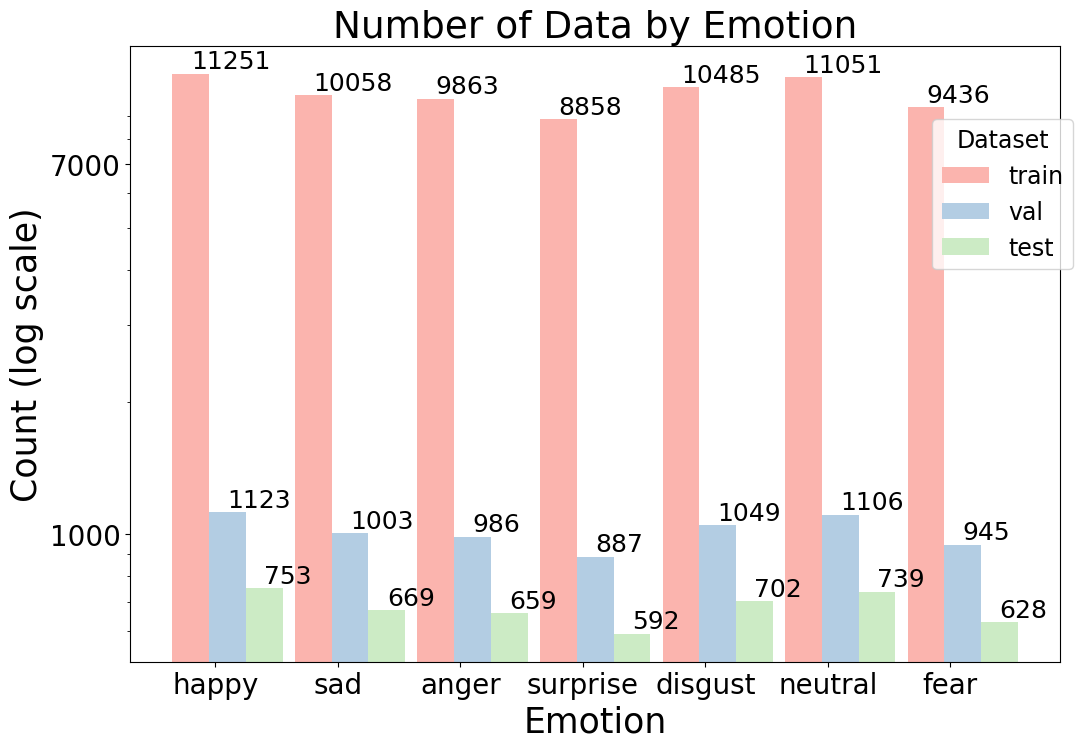

In [ ]:
import tensorflow as tf
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import matplotlib as mpl


# TFRecord 파일 경로 리스트
tfrecord_paths = [
    '/content/drive/MyDrive/01_27_new/0127_YES_Z_train.tfrecord',
    '/content/drive/MyDrive/01_27_new/0127_YES_Z_val.tfrecord',
    '/content/drive/MyDrive/01_27_new/0127_YES_Z_test.tfrecord'
]

# 감정 레이블 정의
emotion_labels = {
    "happy": 0, "sad": 1, "anger": 2, "surprise": 3, "disgust": 4, "neutral": 5, "fear": 6,
}

# TFRecord 파싱 함수
def parse_tfrecord_function(example_proto):
    feature_description = {
        'image': tf.io.FixedLenFeature([], tf.string),
        'label': tf.io.FixedLenFeature([], tf.int64)
    }
    return tf.io.parse_single_example(example_proto, feature_description)

# 각 TFRecord 파일에 대해 처리
emotion_counts = []
for tfrecord_path in tfrecord_paths:
    # TFRecord 데이터셋 로드
    dataset = tf.data.TFRecordDataset(tfrecord_path).map(parse_tfrecord_function)

    # 레이블 별 데이터 카운트
    label_count = Counter()
    for record in dataset:
        label = record['label'].numpy()
        label_count[label] += 1

    # 감정 레이블로 변환하여 저장
    emotion_count = {emotion: label_count[label] for emotion, label in emotion_labels.items()}
    emotion_counts.append(emotion_count)

# 글자 크기 설정
mpl.rcParams['font.size'] = 20

# 막대 그래프 생성
plt.figure(figsize=(12, 8))
for i, emotion_count in enumerate(emotion_counts):
    # 감정 레이블과 개수를 분리
    emotions = list(emotion_count.keys())
    counts = list(emotion_count.values())

    # 막대 그래프 추가 (바의 위치를 조정하여 겹치지 않게 함)
    bars = plt.bar([x + 0.3* i for x in range(len(emotions))], counts, color=plt.cm.Pastel1.colors[i], width=0.3)

    # 레이블 추가
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2.0, yval, int(yval), va='bottom', fontsize=18)  # va: vertical alignment

# 그래프 제목 및 레이블 설정
plt.title('Number of Data by Emotion', fontsize=27)
plt.xticks([x + 0.2 for x in range(len(emotions))], emotions)
plt.xlabel('Emotion', fontsize=25)
plt.ylabel('Count (log scale)', fontsize=25)

# y축을 로그 스케일로 조정
plt.yscale('log')

# y축 레이블 설정
plt.yticks([1000, 7000], ['1000', '7000'])

# 레전드 설정
labels = ['train', 'val', 'test']
plt.legend(labels, title='Dataset', title_fontsize='17', fontsize='17', bbox_to_anchor=(0.85, 0.9))

# 그래프 출력
plt.show()